In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
!ls /content/drive/MyDrive/Model

dataset.zip  Melanoma.zip


In [ ]:
import zipfile
zif_ref = zipfile.ZipFile("/content/drive/MyDrive/Model/dataset.zip")
zif_ref.extractall()
zif_ref.close()

In [ ]:
import os

# Get the directory where the files were extracted
extracted_dir = "/content/dataset"  # Assuming the zip file's contents are extracted into a directory with the same name

# Count the number of files and/or directories within the extracted directory
total_files = 0
for base, _, files in os.walk(extracted_dir):
    for Files in files:
        total_files += 1

print(f"Total number of data items (files) in the dataset: {total_files}")

Total number of data items (files) in the dataset: 3339


In [ ]:
import tensorflow as tf
import numpy as np
import random
import os

seed = 42
tf.random.set_seed(seed)
np.random.seed(seed)
random.seed(seed)
os.environ['PYTHONHASHSEED'] = str(seed)

In [ ]:
import os
import random
import shutil

base_dir = "/content/dataset"
output_dir = "/content/split_dataset"

train_ratio = 0.7
val_ratio = 0.2
test_ratio = 0.1

random.seed(42)

for class_name in os.listdir(base_dir):
    class_path = os.path.join(base_dir, class_name)
    images = os.listdir(class_path)

    random.shuffle(images)

    total = len(images)
    train_split = int(total * train_ratio)
    val_split = int(total * (train_ratio + val_ratio))

    train_images = images[:train_split]
    val_images = images[train_split:val_split]
    test_images = images[val_split:]

    for split_name, split_images in zip(
        ["train", "val", "test"],
        [train_images, val_images, test_images]
    ):
        split_class_dir = os.path.join(output_dir, split_name, class_name)
        os.makedirs(split_class_dir, exist_ok=True)

        for img in split_images:
            shutil.copy(
                os.path.join(class_path, img),
                os.path.join(split_class_dir, img)
            )

print("Split selesai.")

Split selesai.


In [ ]:
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

img_size = (224,224)
batch_size = 32

datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input
)

train_data = datagen.flow_from_directory(
    "/content/split_dataset/train",
    target_size=img_size,
    batch_size=batch_size,
    class_mode='categorical'
)

val_data = datagen.flow_from_directory(
    "/content/split_dataset/val",
    target_size=img_size,
    batch_size=batch_size,
    class_mode='categorical'
)

test_data = datagen.flow_from_directory(
    "/content/split_dataset/test",
    target_size=img_size,
    batch_size=batch_size,
    class_mode='categorical',
    shuffle=False
)

Found 2336 images belonging to 3 classes.
Found 666 images belonging to 3 classes.
Found 336 images belonging to 3 classes.


In [ ]:
train_data.class_indices

{'Melanoma': 0, 'NonSkin': 1, 'NotMelanoma': 2}

In [ ]:
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

train_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input,
    rotation_range=15,
    width_shift_range=0.1,
    height_shift_range=0.1,
    zoom_range=0.1,
    horizontal_flip=True,
    fill_mode='nearest'
)

val_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input
)

test_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input
)

train_data = train_datagen.flow_from_directory(
    "/content/split_dataset/train",
    target_size=(224,224),
    batch_size=32,
    class_mode="categorical"
)

validation_data = val_datagen.flow_from_directory(
    "/content/split_dataset/val",
    target_size=(224,224),
    batch_size=32,
    class_mode="categorical"
)

test_data = test_datagen.flow_from_directory(
    "/content/split_dataset/test",
    target_size=(224,224),
    batch_size=32,
    class_mode="categorical",
    shuffle=False
)

Found 2336 images belonging to 3 classes.
Found 666 images belonging to 3 classes.
Found 336 images belonging to 3 classes.


In [ ]:
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D, Dropout
from tensorflow.keras.models import Model

base_model = MobileNetV2(
    weights='imagenet',
    include_top=False,
    input_shape=(224,224,3)
)

# Freeze backbone (tahap awal)
base_model.trainable = False

x = base_model.output
x = GlobalAveragePooling2D()(x)
x = Dropout(0.3)(x)
output = Dense(3, activation='softmax')(x)

model = Model(inputs=base_model.input, outputs=output)

model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1 (Conv2D)      │ (None, 112, 112,  │        864 │ input_layer_1[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bn_Conv1            │ (None, 112, 112,  │        128 │ Conv1[0][0]       │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1_relu (ReLU)   │ (None, 112, 112,  │          0 │ bn_Conv1[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        288 │ Conv1_relu[0][0]  │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        128 │ expanded_conv_de… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │          0 │ expanded_conv_de… │
│ (ReLU)              │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │        512 │ expanded_conv_de… │
│ (Conv2D)            │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │         64 │ expanded_conv_pr… │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand      │ (None, 112, 112,  │      1,536 │ expanded_conv_pr… │
│ (Conv2D)            │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_BN   │ (None, 112, 112,  │        384 │ block_1_expand[0… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_relu │ (None, 112, 112,  │          0 │ block_1_expand_B… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_pad         │ (None, 113, 113,  │          0 │ block_1_expand_r… │
│ (ZeroPadding2D)     │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise   │ (None, 56, 56,    │        864 │ block_1_pad[0][0] │
│ (DepthwiseConv2D)   │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │        384 │ block_1_depthwis… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │          0 │ block_1_depthwis… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_project     │ (None, 56, 56,    │      2,304 │ block_1_depthwis

 Total params: 2,261,827 (8.63 MB)

 Trainable params: 3,843 (15.01 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [ ]:
from tensorflow.keras.callbacks import EarlyStopping

early_stop = EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)

In [ ]:
history = model.fit(
    train_data,
    validation_data=validation_data,
    epochs=15,
    callbacks=[early_stop]
)

/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/15
73/73 ━━━━━━━━━━━━━━━━━━━━ 60s 712ms/step - accuracy: 0.6156 - loss: 0.8682 - val_accuracy: 0.8288 - val_loss: 0.3501
Epoch 2/15
73/73 ━━━━━━━━━━━━━━━━━━━━ 43s 588ms/step - accuracy: 0.8304 - loss: 0.3797 - val_accuracy: 0.8679 - val_loss: 0.3040
Epoch 3/15
73/73 ━━━━━━━━━━━━━━━━━━━━ 43s 587ms/step - accuracy: 0.8382 - loss: 0.3536 - val_accuracy: 0.8724 - val_loss: 0.2763
Epoch 4/15
73/73 ━━━━━━━━━━━━━━━━━━━━ 43s 588ms/step - accuracy: 0.8643 - loss: 0.3010 - val_accuracy: 0.8604 - val_loss: 0.3052
Epoch 5/15
73/73 ━━━━━━━━━━━━━━━━━━━━ 43s 590ms/step - accuracy: 0.8584 - loss: 0.3159 - val_accuracy: 0.8814 - val_loss: 0.2604
Epoch 6/15
73/73 ━━━━━━━━━━━━━━━━━━━━ 44s 598ms/step - accuracy: 0.8557 - loss: 0.3232 - val_accuracy: 0.8844 - val_loss: 0.2534
Epoch 7/15
73/73 ━━━━━━━━━━━━━━━━━━━━ 43s 588ms/step - accuracy: 0.8800 - loss: 0.2781 - val_accuracy: 0.8844 - val_loss: 0.2518
Epoch 8/15
73/73 ━━━━━━━━━━━━━━━━━━━━ 43s 588ms/step - accuracy: 0.8742 - loss: 0.2699 - val_accu

In [ ]:
test_loss, test_acc = model.evaluate(test_data)
print("Test Accuracy:", test_acc)

11/11 ━━━━━━━━━━━━━━━━━━━━ 7s 644ms/step - accuracy: 0.8415 - loss: 0.3336
Test Accuracy: 0.8541666865348816


11/11 ━━━━━━━━━━━━━━━━━━━━ 12s 720ms/step


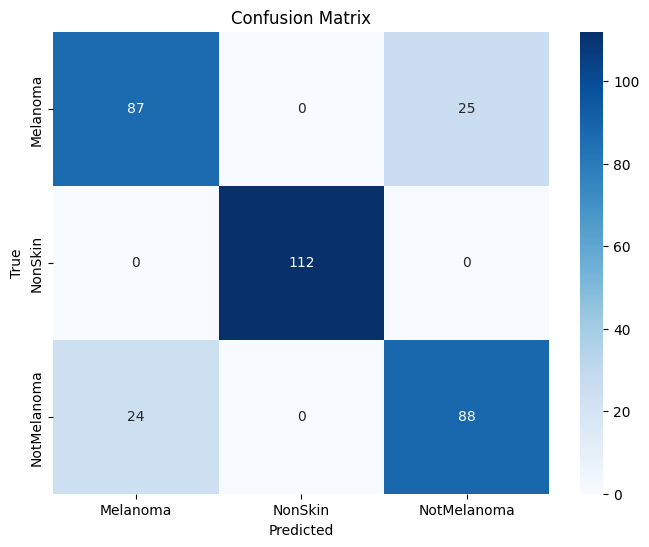

              precision    recall  f1-score   support

    Melanoma       0.78      0.78      0.78       112
     NonSkin       1.00      1.00      1.00       112
 NotMelanoma       0.78      0.79      0.78       112

    accuracy                           0.85       336
   macro avg       0.85      0.85      0.85       336
weighted avg       0.85      0.85      0.85       336



In [ ]:
import numpy as np
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt

predictions = model.predict(test_data)
y_pred = np.argmax(predictions, axis=1)
y_true = test_data.classes

class_names = list(test_data.class_indices.keys())

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names,
            yticklabels=class_names)
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix')
plt.show()

print(classification_report(y_true, y_pred, target_names=class_names))

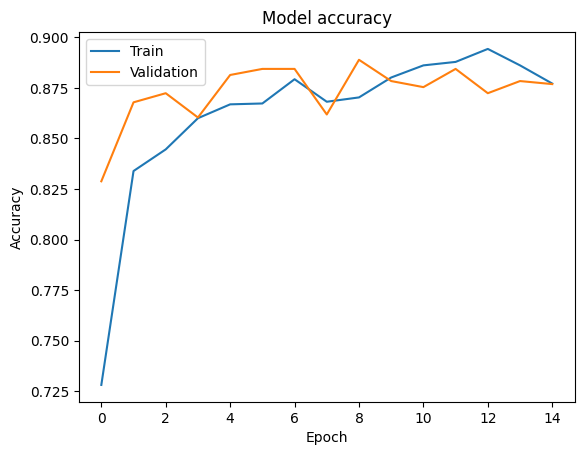

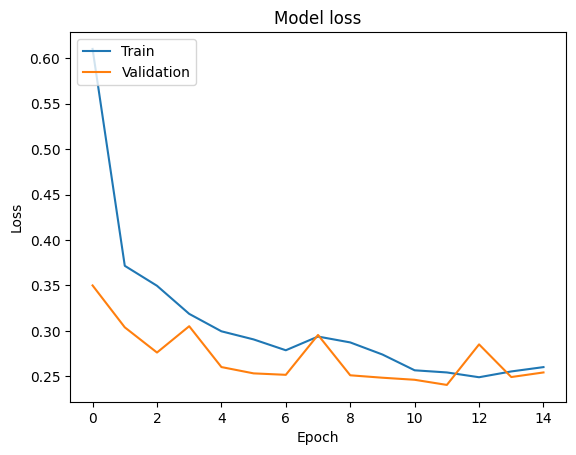

In [ ]:
# plot dari hasil training model di atas

import matplotlib.pyplot as plt

# Plot training & validation accuracy values
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title('Model accuracy')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.legend(['Train', 'Validation'], loc='upper left')
plt.show()

# Plot training & validation loss values
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('Model loss')
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.legend(['Train', 'Validation'], loc='upper left')
plt.show()

In [ ]:
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt


# Classification Report
print(f"\n Classification Report:\n")

report = classification_report(y_true, y_pred, target_names=class_names)
print(report)


 Classification Report:

              precision    recall  f1-score   support

    Melanoma       0.81      0.78      0.79       112
     NonSkin       1.00      1.00      1.00       112
 NotMelanoma       0.79      0.82      0.80       112

    accuracy                           0.87       336
   macro avg       0.87      0.87      0.87       336
weighted avg       0.87      0.87      0.87       336



In [ ]:
model.save("model_melanoma_baru.h5")